# Installations and Imports

In [1]:
!pip install vaderSentiment
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 32.9 MB/s  0:00:00


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression,SGDClassifier
from sklearn.metrics import accuracy_score,classification_report

import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords

import spacy

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

import gensim
import gensim.corpora as corpora
from gensim.models.coherencemodel import CoherenceModel
from gensim.models import LsiModel,TfidfModel



# Dataset Exploration

In [8]:
plt.rcParams["figure.figsize"]=(12,8)
default_plot_colour = "#00bfbf"

In [9]:
data = pd.read_csv("fake_news_data.csv")

In [10]:
data.head()

,title,text,date,fake_or_factual
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News


In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198 entries, 0 to 197
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   title            198 non-null    object
 1   text             198 non-null    object
 2   date             198 non-null    object
 3   fake_or_factual  198 non-null    object
dtypes: object(4)
memory usage: 6.3+ KB


Text(0.5, 1.0, 'Count of Article Classification')

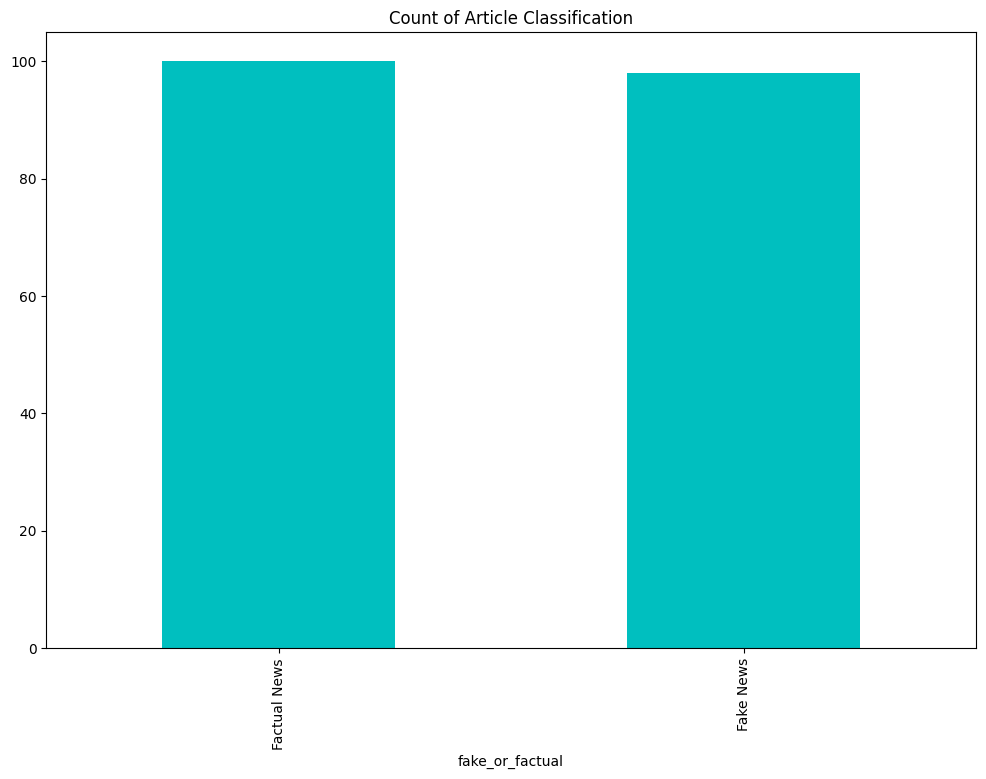

In [12]:
data["fake_or_factual"].value_counts().plot(kind="bar",color=default_plot_colour)
plt.title("Count of Article Classification")

# Part of Speech and Named Entities

In [13]:
nlp=spacy.load("en_core_web_sm")

In [14]:
columns=["token","ner_tag","pos_tag"]
def extract_token_tags(doc:spacy.tokens.doc.Doc):
  return [(item.text,item.ent_type_,item.pos_)for item in doc]

In [15]:
fake_news = data[data["fake_or_factual"]=="Fake News"]
fake_spacydocs = list(nlp.pipe(fake_news["text"]))

fake_tagsdf=[]
for doc in fake_spacydocs:
  tags=extract_token_tags(doc)
  tags=pd.DataFrame(tags,columns=columns)
  fake_tagsdf.append(tags)

fake_tagsdf=pd.concat(fake_tagsdf)

In [16]:
fake_tagsdf.head()

,token,ner_tag,pos_tag
0,There,,PRON
1,are,,VERB
2,two,CARDINAL,NUM
3,small,,ADJ
4,problems,,NOUN


In [17]:
fact_news = data[data["fake_or_factual"]=="Factual News"]
fact_spacydocs = list(nlp.pipe(fact_news["text"]))
fact_tagsdf=[]
for doc in fact_spacydocs:
  tags=extract_token_tags(doc)
  tags=pd.DataFrame(tags,columns=columns)
  fact_tagsdf.append(tags)

fact_tagsdf=pd.concat(fact_tagsdf)

In [18]:
fact_tagsdf.head()

,token,ner_tag,pos_tag
0,WASHINGTON,GPE,PROPN
1,(,,PUNCT
2,Reuters,ORG,PROPN
3,),,PUNCT
4,-,,PUNCT


POS

In [26]:
pos_counts_fake=fake_tagsdf.groupby(["token","pos_tag"]).size().reset_index(name="counts").sort_values(by="counts",ascending=False,ignore_index=True)

In [27]:
pos_counts_fake.head()

,token,pos_tag,counts
0,",",PUNCT,1908
1,the,DET,1834
2,.,PUNCT,1530
3,of,ADP,922
4,and,CCONJ,875


In [36]:
pos_counts_fake.groupby("pos_tag")["counts"].count().reset_index().sort_values(by="counts",ascending=False,ignore_index=True)

,pos_tag,counts
0,NOUN,2586
1,VERB,1817
2,PROPN,1672
3,ADJ,882
4,ADV,413
5,NUM,221
6,PRON,96
7,ADP,89
8,AUX,62
9,SCONJ,51


In [37]:
pos_counts_fake[pos_counts_fake["pos_tag"]=="NOUN"][:15]

,token,pos_tag,counts
62,people,NOUN,77
72,t,NOUN,65
79,president,NOUN,58
83,women,NOUN,55
90,time,NOUN,52
102,year,NOUN,44
105,campaign,NOUN,44
113,government,NOUN,41
116,law,NOUN,40
117,years,NOUN,40


In [38]:
pos_counts_fact=fact_tagsdf.groupby(["token","pos_tag"]).size().reset_index(name="counts").sort_values(by="counts",ascending=False,ignore_index=True)

In [39]:
pos_counts_fact.head()

,token,pos_tag,counts
0,the,DET,1903
1,",",PUNCT,1698
2,.,PUNCT,1382
3,of,ADP,884
4,a,DET,789


In [40]:
pos_counts_fact.groupby("pos_tag")["counts"].count().reset_index().sort_values(by="counts",ascending=False,ignore_index=True)

,pos_tag,counts
0,NOUN,2179
1,VERB,1539
2,PROPN,1379
3,ADJ,747
4,ADV,263
5,NUM,205
6,PRON,79
7,ADP,70
8,AUX,43
9,SCONJ,42


In [41]:
pos_counts_fact[pos_counts_fact["pos_tag"]=="NOUN"][:15]

,token,pos_tag,counts
55,government,NOUN,71
60,year,NOUN,64
64,state,NOUN,57
71,bill,NOUN,55
74,administration,NOUN,51
78,president,NOUN,49
79,election,NOUN,48
86,people,NOUN,45
87,order,NOUN,45
96,campaign,NOUN,42


NER

In [42]:
top_entities_fake=fake_tagsdf[fake_tagsdf["ner_tag"]!=""].groupby(["token","ner_tag"]).size().reset_index(name="counts").sort_values(by="counts",ascending=False)

In [43]:
top_entities_fact=fact_tagsdf[fact_tagsdf["ner_tag"]!=""].groupby(["token","ner_tag"]).size().reset_index(name="counts").sort_values(by="counts",ascending=False)

In [44]:
ner_palette = {
    'ORG': sns.color_palette("Set2").as_hex()[0],
    'GPE': sns.color_palette("Set2").as_hex()[1],
    'NORP': sns.color_palette("Set2").as_hex()[2],
    'PERSON': sns.color_palette("Set2").as_hex()[3],
    'DATE': sns.color_palette("Set2").as_hex()[4],
    'CARDINAL': sns.color_palette("Set2").as_hex()[5],
    'PERCENT': sns.color_palette("Set2").as_hex()[6]
}

[Text(0.5, 1.0, 'Most Common Named Entities in Fake News')]

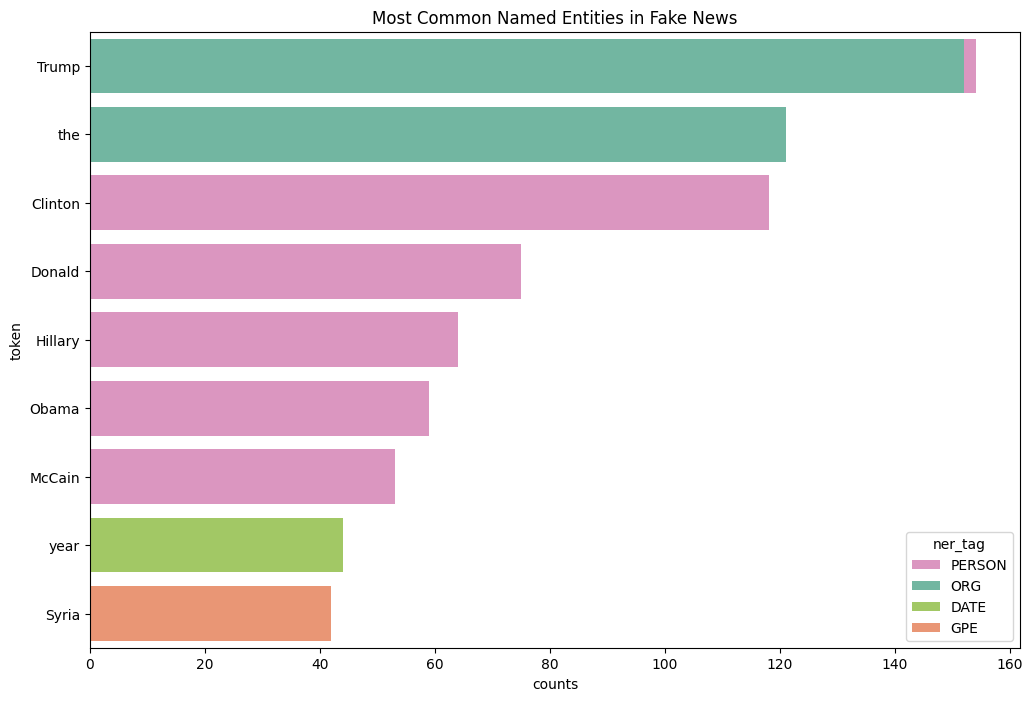

In [47]:
sns.barplot(
    x = 'counts',
    y = 'token',
    hue = 'ner_tag',
    palette = ner_palette,
    data = top_entities_fake[:10],
    orient = 'h',
    dodge = False
).set(title="Most Common Named Entities in Fake News")

[Text(0.5, 1.0, 'Most Common Named Entities in Fact News')]

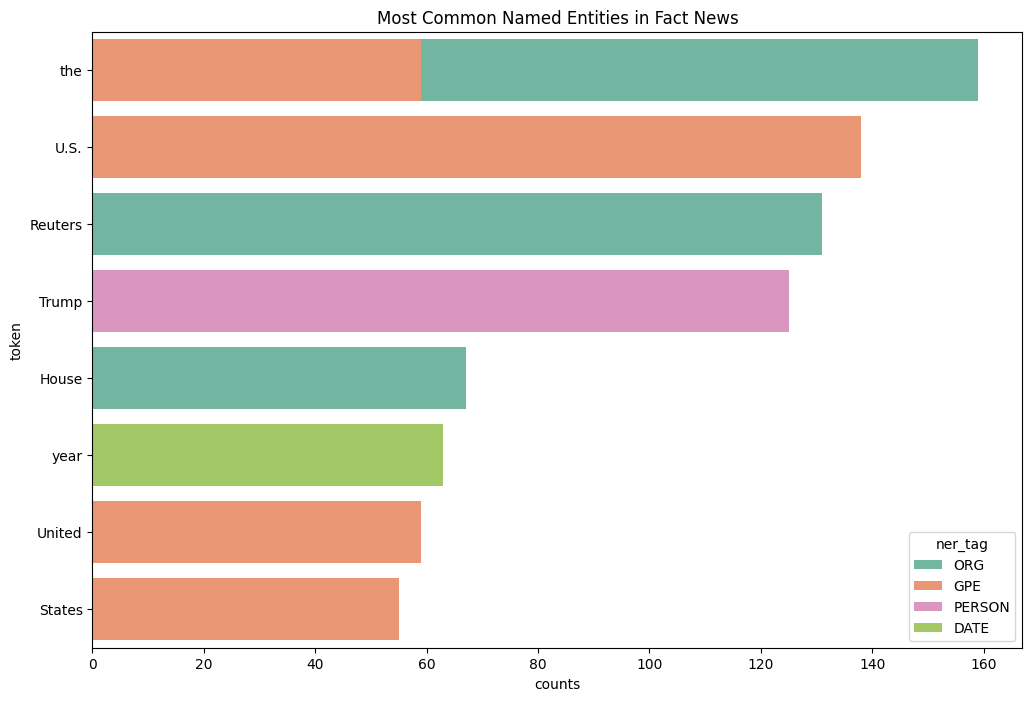

In [48]:
sns.barplot(
    x = 'counts',
    y = 'token',
    hue = 'ner_tag',
    palette = ner_palette,
    data = top_entities_fact[:10],
    orient = 'h',
    dodge = False
).set(title="Most Common Named Entities in Fact News")

# Data Preprocessing

In [49]:
data.head()

,title,text,date,fake_or_factual
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News


In [50]:
data['text_clean'] = data["text"].apply(lambda x: re.sub(r"^[^-]*-\s", "", x))
data['text_clean'] = data['text_clean'].str.lower()
data['text_clean'] = data["text_clean"].apply(lambda x: re.sub(r"([^\w\s])", "", x))

In [51]:
nltk.download("stopwords")
en_stopwords = stopwords.words('english')
data['text_clean'] = data['text_clean'].apply(lambda x: ' '.join([word for word in x.split() if word not in en_stopwords]))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [52]:
lemmatizer = WordNetLemmatizer()
nltk.download("punkt_tab")
nltk.download("wordnet")
data['text_clean'] = data["text_clean"].apply(lambda x: word_tokenize(x))
data['text_clean'] = data['text_clean'].apply(lambda tokens: [lemmatizer.lemmatize(token) for token in tokens])

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [64]:
tokens_clean = sum(data['text_clean'], [])
unigrams = pd.Series(nltk.ngrams(tokens_clean, 1)).value_counts().rename_axis("token").reset_index()[:10]
unigrams["token"] = unigrams["token"].str[0]
unigrams

,token,count
0,trump,580
1,said,580
2,u,277
3,state,275
4,president,259
5,would,226
6,one,160
7,clinton,141
8,year,139
9,republican,137


/tmp/ipykernel_2183/127668928.py:1: UserWarning: 
The palette list has fewer values (1) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(x="count",


[Text(0.5, 1.0, 'Most Common Unigrams After Preprocessing')]

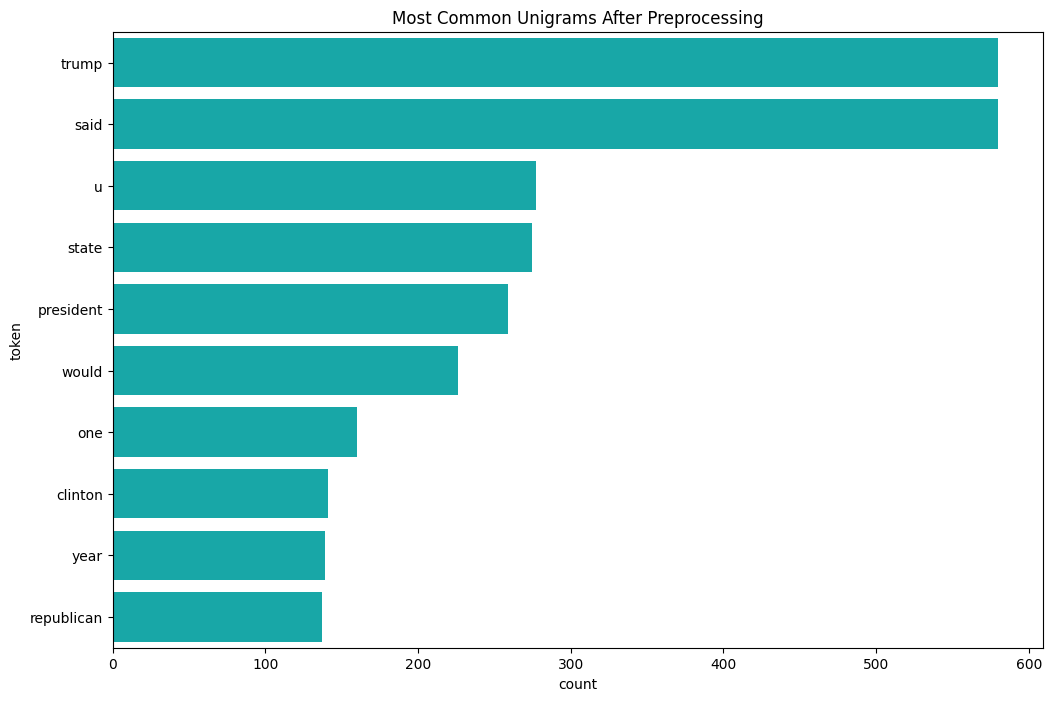

In [65]:
sns.barplot(x="count",
            y="token",
            data=unigrams,
            orient="h",
            palette=[default_plot_colour],
            hue="token", legend=False)\
.set(title="Most Common Unigrams After Preprocessing")

In [67]:
bigrams = pd.Series(nltk.ngrams(tokens_clean, 2)).value_counts().rename_axis("token").reset_index()[:10]
bigrams["token"]=bigrams["token"].str[0]+" "+bigrams["token"].str[1]
bigrams

,token,count
0,donald trump,113
1,united state,84
2,white house,74
3,president donald,47
4,hillary clinton,39
5,new york,33
6,supreme court,30
7,image via,29
8,official said,26
9,trump administration,26


/tmp/ipykernel_2183/2550972594.py:1: UserWarning: 
The palette list has fewer values (1) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(x="count",


[Text(0.5, 1.0, 'Most Common BiGrams After Preprocessing')]

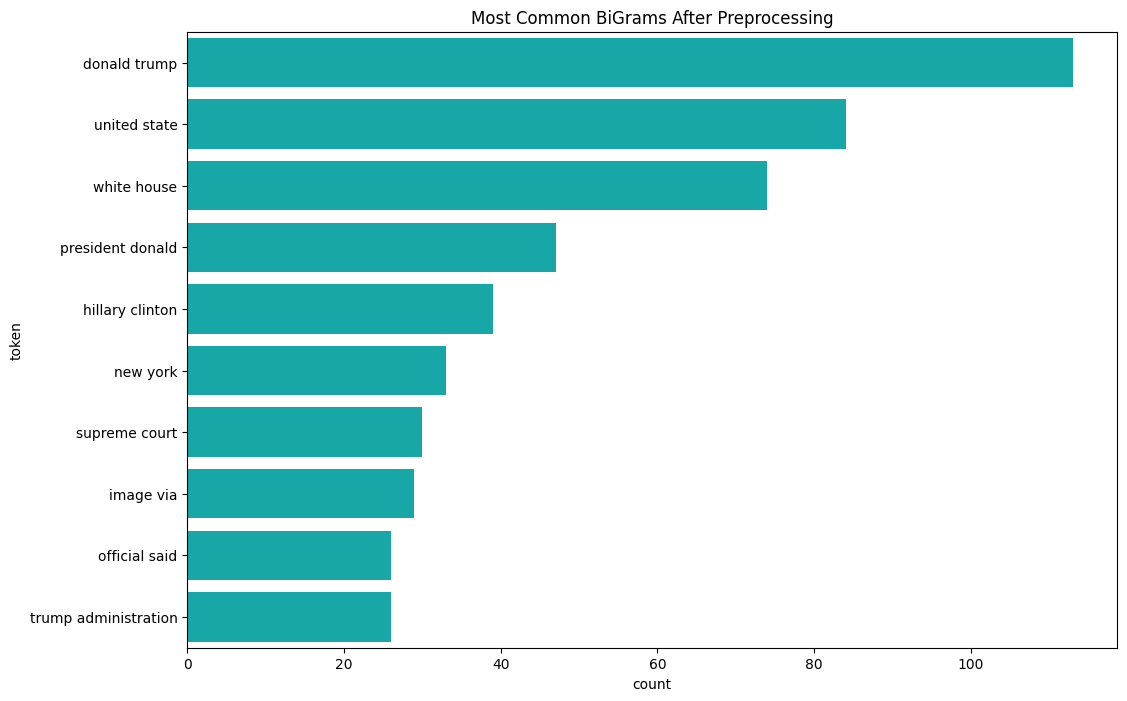

In [68]:
sns.barplot(x="count",
            y="token",
            data=bigrams,
            orient="h",
            palette=[default_plot_colour],
            hue="token", legend=False)\
.set(title="Most Common BiGrams After Preprocessing")

# Sentiment Analysis

In [69]:
vader_sentiment = SentimentIntensityAnalyzer()

In [70]:
data['vader_sentiment_score'] = data['text'].apply(lambda x: vader_sentiment.polarity_scores(x)['compound'])

In [71]:
data.head()

,title,text,date,fake_or_factual,text_clean,vader_sentiment_score
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News,"[two, small, problem, analogy, susan, jesus, m...",-0.3660
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News,"[buried, trump, bonkers, interview, new, york,...",-0.8197
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News,"[woman, make, 50, percent, country, grossly, u...",0.9779
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News,"[u, defense, secretary, jim, mattis, said, mon...",-0.3400
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News,"[northern, ireland, political, party, rapidly,...",0.8590


In [72]:
bins = [-1, -0.1, 0.1, 1]
names = ['negative', 'neutral', 'positive']
data['vader_sentiment_label'] = pd.cut(data['vader_sentiment_score'], bins, labels=names)

In [73]:
data.head()

,title,text,date,fake_or_factual,text_clean,vader_sentiment_score,vader_sentiment_label
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News,"[two, small, problem, analogy, susan, jesus, m...",-0.3660,negative
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News,"[buried, trump, bonkers, interview, new, york,...",-0.8197,negative
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News,"[woman, make, 50, percent, country, grossly, u...",0.9779,positive
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News,"[u, defense, secretary, jim, mattis, said, mon...",-0.3400,negative
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News,"[northern, ireland, political, party, rapidly,...",0.8590,positive


<Axes: xlabel='vader_sentiment_label'>

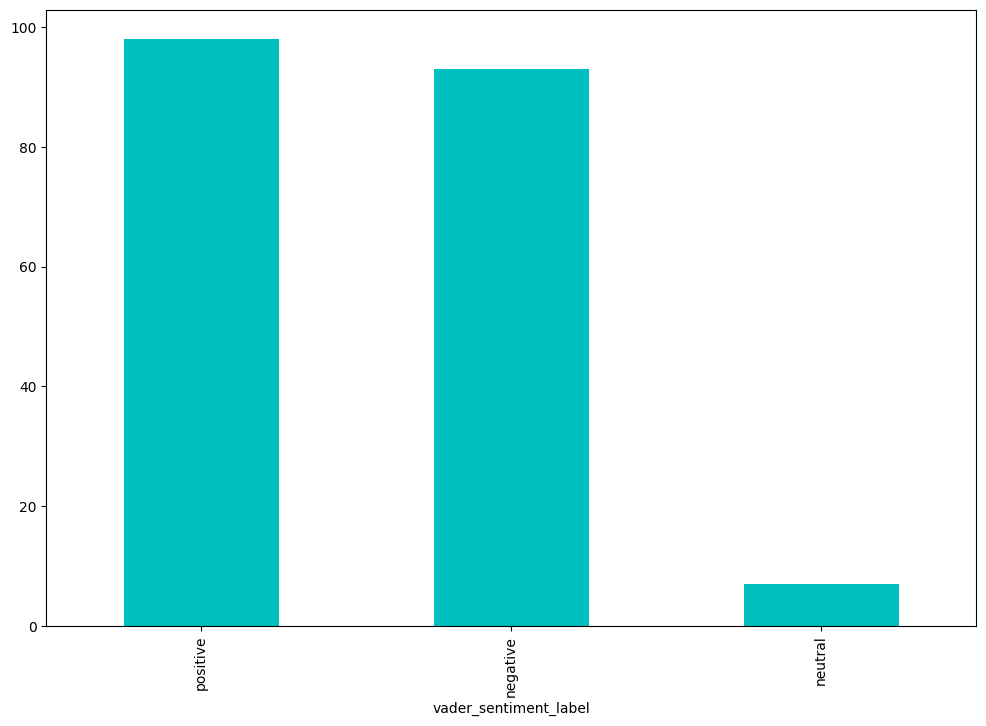

In [74]:
data['vader_sentiment_label'].value_counts().plot.bar(color=default_plot_colour)

/tmp/ipykernel_2183/6889798.py:1: UserWarning: The palette list has more values (6) than needed (3), which may not be intended.
  sns.countplot(


[Text(0.5, 1.0, 'Sentiment by News Type')]

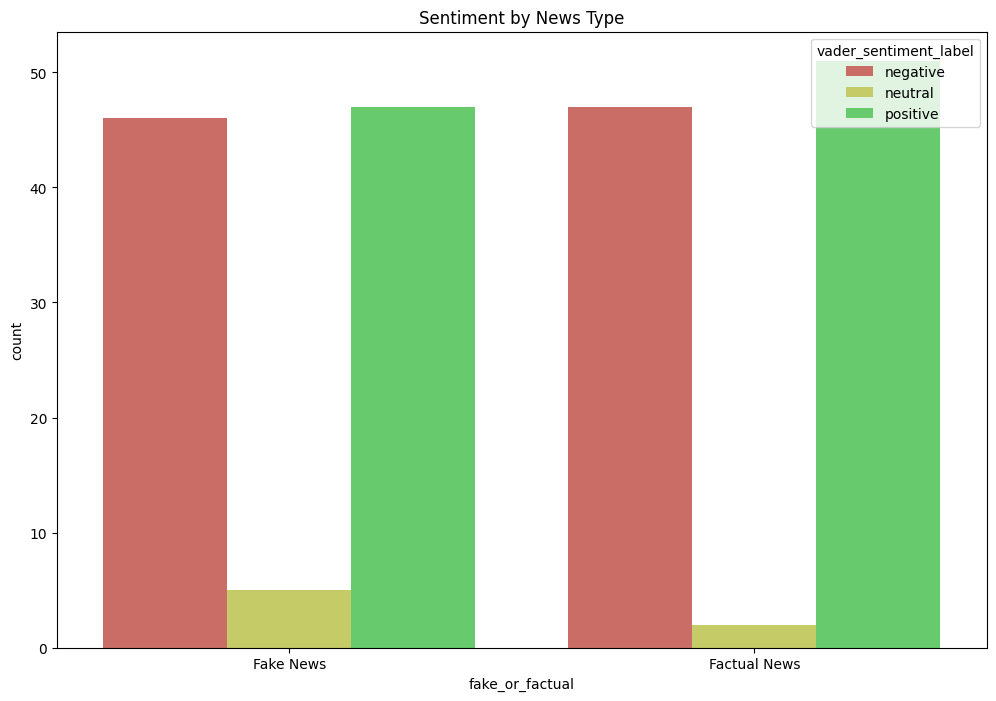

In [75]:
sns.countplot(
    x = 'fake_or_factual',
    hue = 'vader_sentiment_label',
    palette = sns.color_palette("hls"),
    data = data
).set(title = "Sentiment by News Type")

# Topic Modelling

In [80]:
fake_news_text = data[data['fake_or_factual']=="Fake News"]["text_clean"].reset_index(drop=True)

In [81]:
fake_news_text

,text_clean
0,"[two, small, problem, analogy, susan, jesus, m..."
1,"[buried, trump, bonkers, interview, new, york,..."
2,"[woman, make, 50, percent, country, grossly, u..."
3,"[shame, teen, vogue, maxine, water, guest, tee..."
4,"[former, white, house, press, secretary, obama..."
...,...
93,"[jon, ritzheimer, infamous, hater, muslim, one..."
94,"[well, take, long, look, first, beastiality, m..."
95,"[florida, toxic, dangerous, stand, ground, gun..."
96,"[politico, report, almost, neckandneck, race, ..."


In [82]:
dictionary_fake = corpora.Dictionary(fake_news_text)

In [83]:
doc_term_fake = [dictionary_fake.doc2bow(text) for text in fake_news_text]

lda

In [84]:
coherence_values=[]
model_list=[]
min_topics=2
max_topics=11

for num_topics_i in range(min_topics,max_topics+1):
  model=gensim.models.LdaModel(doc_term_fake,num_topics=num_topics_i,id2word=dictionary_fake,passes=10)
  model_list.append(model)
  coherence_model=CoherenceModel(model=model,texts=fake_news_text,dictionary=dictionary_fake,coherence='c_v')
  coherence_values.append(coherence_model.get_coherence())

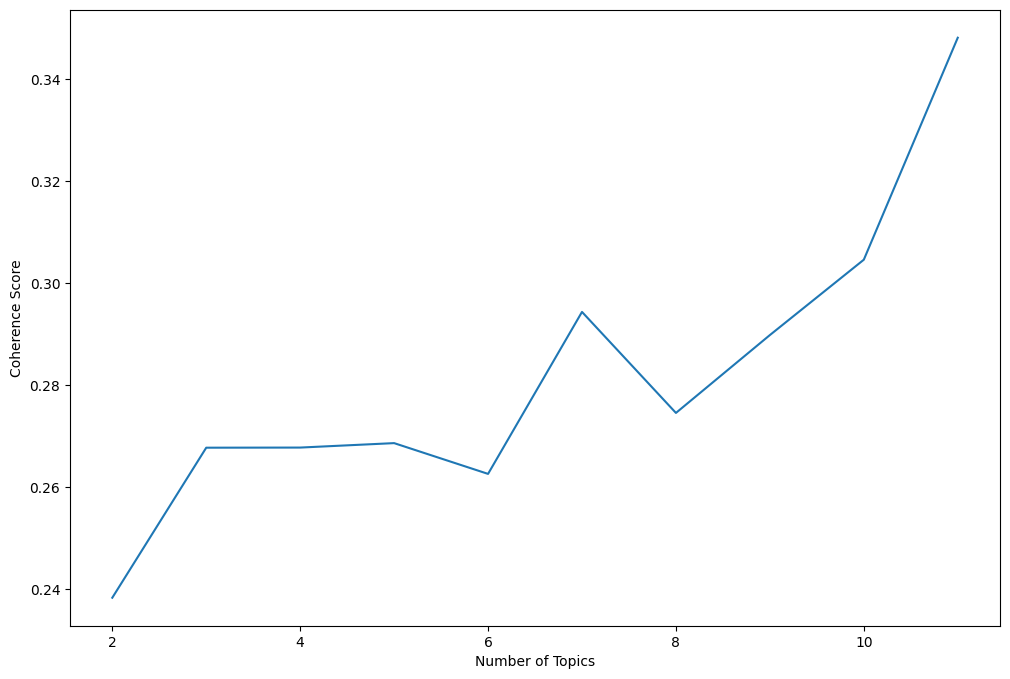

In [85]:
plt.plot(range(min_topics,max_topics+1),coherence_values)
plt.xlabel("Number of Topics")
plt.ylabel("Coherence Score")
plt.show()

In [86]:
num_topics_lda=7
lda_model=gensim.models.LdaModel(corpus=doc_term_fake,num_topics=num_topics_lda,id2word=dictionary_fake,passes=10)

In [87]:
lda_model.print_topics(num_topics=num_topics_lda,num_words=10)

[(0,
  '0.012*"trump" + 0.007*"hillary" + 0.006*"clinton" + 0.006*"said" + 0.005*"president" + 0.004*"obama" + 0.004*"republican" + 0.004*"tax" + 0.004*"rich" + 0.004*"think"'),
 (1,
  '0.009*"state" + 0.006*"said" + 0.006*"obama" + 0.005*"school" + 0.004*"president" + 0.004*"tobacco" + 0.004*"year" + 0.003*"also" + 0.003*"go" + 0.003*"city"'),
 (2,
  '0.012*"trump" + 0.006*"republican" + 0.006*"flynn" + 0.005*"state" + 0.004*"one" + 0.004*"said" + 0.004*"donald" + 0.004*"would" + 0.004*"woman" + 0.004*"president"'),
 (3,
  '0.007*"would" + 0.007*"email" + 0.006*"clinton" + 0.006*"woman" + 0.006*"law" + 0.006*"student" + 0.005*"state" + 0.005*"want" + 0.005*"record" + 0.005*"department"'),
 (4,
  '0.011*"trump" + 0.010*"food" + 0.009*"stamp" + 0.008*"million" + 0.006*"fraud" + 0.005*"know" + 0.004*"penny" + 0.004*"back" + 0.004*"store" + 0.004*"year"'),
 (5,
  '0.027*"trump" + 0.008*"clinton" + 0.006*"president" + 0.005*"woman" + 0.005*"donald" + 0.005*"republican" + 0.004*"hillary" + 

lsa

In [88]:
def tfidf_corpus(doc_term_matrix):
  tfidf=TfidfModel(doc_term_matrix,normalize=True)
  corpus_tfidf=tfidf[doc_term_matrix]
  return corpus_tfidf

In [89]:
def get_coherence_scores(corpus,dictionary,text,min_topics,max_topics):
  coherence_values=[]
  model_list=[]
  for num_topics_i in range(min_topics,max_topics+1):
    model=LsiModel(corpus=corpus,num_topics=num_topics_i,id2word=dictionary,)
    model_list.append(model)
    coherence_model=CoherenceModel(model=model,texts=text,dictionary=dictionary,coherence='c_v')
    coherence_values.append(coherence_model.get_coherence())
  plt.plot(range(min_topics,max_topics+1),coherence_values)
  plt.xlabel("Number of Topics")
  plt.ylabel("Coherence Score")
  plt.show()

In [90]:
corpus_tfidf_fake=tfidf_corpus(doc_term_fake)

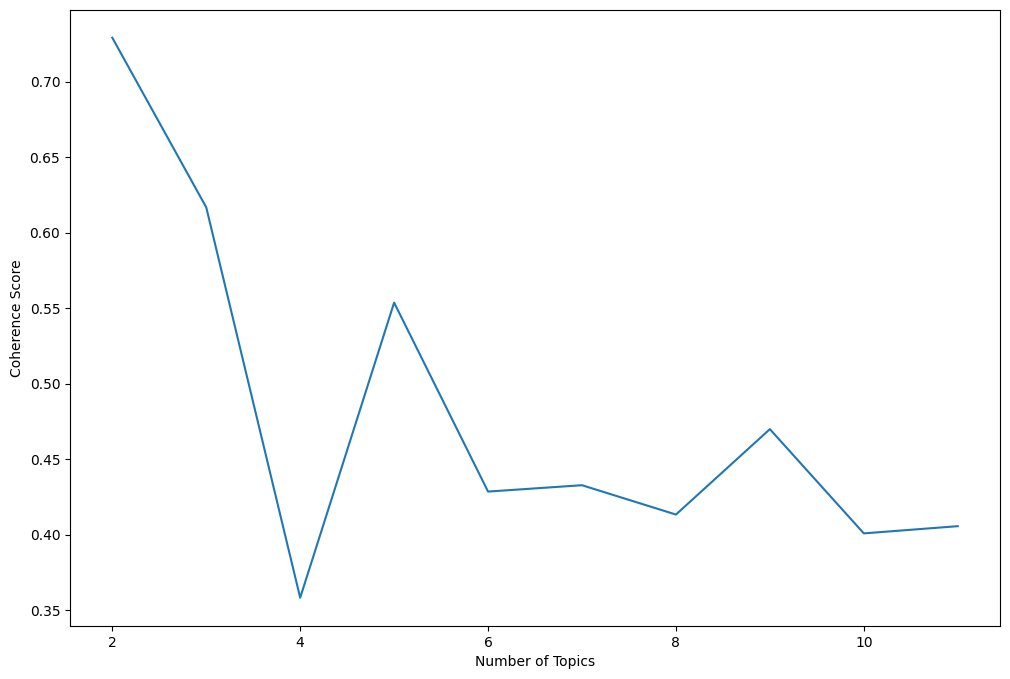

In [91]:
get_coherence_scores(corpus_tfidf_fake,dictionary_fake,fake_news_text,2,11)

In [92]:
lsa_model=LsiModel(corpus=corpus_tfidf_fake,num_topics=7,id2word=dictionary_fake)

In [93]:
lsa_model.print_topics()

[(0,
  '-0.190*"trump" + -0.136*"clinton" + -0.095*"hillary" + -0.094*"obama" + -0.089*"president" + -0.087*"woman" + -0.078*"republican" + -0.077*"party" + -0.077*"flynn" + -0.074*"candidate"'),
 (1,
  '-0.325*"boiler" + -0.284*"acr" + -0.244*"room" + -0.240*"pm" + -0.186*"broadcast" + -0.180*"radio" + -0.142*"animal" + -0.142*"tune" + -0.134*"jay" + -0.132*"episode"'),
 (2,
  '-0.623*"flynn" + -0.182*"immunity" + -0.122*"nana" + -0.116*"mr" + -0.110*"30" + -0.108*"march" + -0.102*"russian" + -0.100*"source" + 0.095*"school" + -0.092*"adviser"'),
 (3,
  '0.217*"clinton" + -0.186*"school" + -0.176*"student" + 0.141*"hillary" + -0.121*"county" + -0.121*"flynn" + 0.110*"sander" + 0.098*"debate" + 0.097*"woman" + 0.091*"nominee"'),
 (4,
  '0.200*"email" + -0.194*"trump" + 0.168*"dnc" + -0.142*"flynn" + 0.126*"clinton" + -0.112*"cruz" + 0.111*"department" + 0.110*"rich" + 0.102*"wikileaks" + 0.099*"sander"'),
 (5,
  '-0.276*"student" + -0.160*"conference" + -0.160*"school" + -0.137*"trump"

# News Categorization

In [94]:
data.head()

,title,text,date,fake_or_factual,text_clean,vader_sentiment_score,vader_sentiment_label
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News,"[two, small, problem, analogy, susan, jesus, m...",-0.3660,negative
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News,"[buried, trump, bonkers, interview, new, york,...",-0.8197,negative
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News,"[woman, make, 50, percent, country, grossly, u...",0.9779,positive
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News,"[u, defense, secretary, jim, mattis, said, mon...",-0.3400,negative
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News,"[northern, ireland, political, party, rapidly,...",0.8590,positive


In [100]:
x=[",".join(map(str,token))for token in data["text_clean"]]

In [101]:
y=data["fake_or_factual"]

In [102]:
countvec=CountVectorizer()

In [103]:
contvec_fit=countvec.fit_transform(x)

In [105]:
bag_of_words=pd.DataFrame(contvec_fit.toarray(),columns=countvec.get_feature_names_out())

In [115]:
x_train,x_test,y_train,y_test=train_test_split(bag_of_words,y,test_size=0.3,random_state=42,stratify=y)

In [116]:
lr=LogisticRegression(random_state=42).fit(x_train,y_train)

In [117]:
y_pred_lr=lr.predict(x_test)

In [118]:
accuracy_score(y_pred_lr,y_test)

0.95

In [119]:
print(classification_report(y_test,y_pred_lr))

              precision    recall  f1-score   support

Factual News       0.91      1.00      0.95        30
   Fake News       1.00      0.90      0.95        30

    accuracy                           0.95        60
   macro avg       0.95      0.95      0.95        60
weighted avg       0.95      0.95      0.95        60



In [120]:
svm=SGDClassifier(random_state=42).fit(x_train,y_train)

In [121]:
y_pred_svm=svm.predict(x_test)

In [122]:
accuracy_score(y_pred_svm,y_test)

0.9333333333333333

In [123]:
print(classification_report(y_test,y_pred_svm))

              precision    recall  f1-score   support

Factual News       0.88      1.00      0.94        30
   Fake News       1.00      0.87      0.93        30

    accuracy                           0.93        60
   macro avg       0.94      0.93      0.93        60
weighted avg       0.94      0.93      0.93        60

